<a href="https://colab.research.google.com/github/zubaeteee20210205109-droid/Thesis/blob/main/Arsenicosis_EfficientNetV2B0_Transformer%20(%205th%20run%20).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [110]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [111]:
# ============================================================
# CELL 1: CHECK GPU
# ============================================================

import tensorflow as tf

print("=" * 60)
print("TensorFlow Version :", tf.__version__)
print("=" * 60)

print("Built with CUDA :", tf.test.is_built_with_cuda())

gpus = tf.config.list_physical_devices("GPU")

print("Available GPUs :", gpus)

if gpus:
    print("\nGPU DETECTED")

    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

    gpu_details = tf.config.experimental.get_device_details(gpus[0])
    print("GPU Name :", gpu_details.get("device_name"))

else:
    print("\nNO GPU DETECTED")
    print("TensorFlow is running on CPU.")

print("=" * 60)

TensorFlow Version : 2.21.0
Built with CUDA : True
Available GPUs : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

GPU DETECTED
GPU Name : Tesla T4


In [112]:
# ============================================================
# CELL 2: AUTOMATIC MULTI-RUN CONFIGURATION
# ============================================================

import os
import re
import random
import numpy as np
import tensorflow as tf

# Use the SAME experiment folder for all five runs
BASE_SAVE_DIR = "/content/drive/MyDrive/Thesis_Experiments"

EXPERIMENT_NAME = (
    "Arsenicosis_EfficientNetV2_Transformer"
)

EXPERIMENT_DIR = os.path.join(
    BASE_SAVE_DIR,
    EXPERIMENT_NAME
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

# Automatically identify the next available run number
existing_runs = []

for folder in os.listdir(EXPERIMENT_DIR):
    match = re.fullmatch(r"Run_(\d+)", folder)

    if match and os.path.isdir(os.path.join(EXPERIMENT_DIR, folder)):
        existing_runs.append(int(match.group(1)))

RUN_NUMBER = max(existing_runs, default=0) + 1

# Automatically assign a different seed to each run
RUN_SEED = 101 * RUN_NUMBER

# Set random seeds
random.seed(RUN_SEED)
np.random.seed(RUN_SEED)
tf.keras.utils.set_random_seed(RUN_SEED)

# Enable deterministic TensorFlow operations where supported
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("Determinism configuration:", e)

print("=" * 60)
print("AUTOMATIC RUN CONFIGURATION")
print("=" * 60)

print("Experiment folder:", EXPERIMENT_DIR)
print("Selected run:", f"Run_{RUN_NUMBER}")
print("Random seed:", RUN_SEED)

print("\nExisting runs:", sorted(existing_runs))
print("New run will be saved separately.")
print("=" * 60)

AUTOMATIC RUN CONFIGURATION
Experiment folder: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer
Selected run: Run_5
Random seed: 505

Existing runs: [1, 2, 3, 4]
New run will be saved separately.


In [113]:
# ============================================================
# CELL 3: COPY DATASETS TO LOCAL SSD
# ============================================================

import os
import shutil

# Google Drive paths
ORIGINAL_SOURCE = "/content/drive/MyDrive/ArsenicSkinImage(BD)/Original"
AUGMENTED_SOURCE = "/content/drive/MyDrive/ArsenicSkinImage(BD)/Augmented"

# Local SSD paths
ORIGINAL_DESTINATION = "/content/Original"
AUGMENTED_DESTINATION = "/content/Augmented"

# Copy Original Dataset
if not os.path.exists(ORIGINAL_DESTINATION):

    print("Copying Original dataset to local SSD...")

    shutil.copytree(
        ORIGINAL_SOURCE,
        ORIGINAL_DESTINATION
    )

    print("Original dataset copied successfully!")

else:
    print("Original dataset already exists in local SSD.")

# Copy Augmented Dataset
if not os.path.exists(AUGMENTED_DESTINATION):

    print("\nCopying Augmented dataset to local SSD...")

    shutil.copytree(
        AUGMENTED_SOURCE,
        AUGMENTED_DESTINATION
    )

    print("Augmented dataset copied successfully!")

else:
    print("Augmented dataset already exists in local SSD.")

print("\nBoth datasets are ready!")

Original dataset already exists in local SSD.
Augmented dataset already exists in local SSD.

Both datasets are ready!


In [114]:
# ============================================================
# CELL 4: CHECK DATASET FOLDERS
# ============================================================

print("ORIGINAL DATASET")

for folder in os.listdir(ORIGINAL_DESTINATION):

    folder_path = os.path.join(ORIGINAL_DESTINATION, folder)

    if os.path.isdir(folder_path):
        print(folder, ":", len(os.listdir(folder_path)), "files")


print("\nAUGMENTED DATASET")

for folder in os.listdir(AUGMENTED_DESTINATION):

    folder_path = os.path.join(AUGMENTED_DESTINATION, folder)

    if os.path.isdir(folder_path):
        print(folder, ":", len(os.listdir(folder_path)), "files")

ORIGINAL DATASET
infacted : 741 files
not_infacted : 546 files

AUGMENTED DATASET
infected : 4446 files
not_infected : 4446 files


In [115]:
# ============================================================
# CELL 5: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import re
import pandas as pd
from pathlib import Path

print("Required libraries imported successfully!")

Required libraries imported successfully!


In [116]:
# ============================================================
# CELL 6: SOURCE ID EXTRACTION
# ============================================================

def get_source_id(filename):

    stem = Path(filename).stem

    source_id = re.sub(
        r"_augmented.*$",
        "",
        stem,
        flags=re.IGNORECASE
    )

    return source_id.strip().lower()

In [117]:
# ============================================================
# CELL 7: COLLECT ORIGINAL AND AUGMENTED IMAGE INFORMATION
# ============================================================

def collect_images(root_dir, dataset_type):

    records = []

    # Map actual folder names to standardized class names
    if dataset_type == "Original":

        class_mapping = {
            "infacted": "infected",
            "not_infacted": "not_infected"
        }

    else:

        class_mapping = {
            "infected": "infected",
            "not_infected": "not_infected"
        }

    for folder_name, class_name in class_mapping.items():

        class_dir = os.path.join(root_dir, folder_name)

        if not os.path.isdir(class_dir):
            print("WARNING: Missing folder:", class_dir)
            continue

        for filename in os.listdir(class_dir):

            file_path = os.path.join(class_dir, filename)

            if os.path.isfile(file_path) and filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            ):

                records.append({
                    "filename": filename,
                    "class_name": class_name,
                    "source_id": get_source_id(filename),
                    "file_path": file_path,
                    "dataset_type": dataset_type
                })

    return pd.DataFrame(
        records,
        columns=[
            "filename",
            "class_name",
            "source_id",
            "file_path",
            "dataset_type"
        ]
    )


# Collect datasets
original_df = collect_images(
    ORIGINAL_DESTINATION,
    "Original"
)

augmented_df = collect_images(
    AUGMENTED_DESTINATION,
    "Augmented"
)

print("=" * 60)
print("ORIGINAL TOTAL IMAGES :", len(original_df))
print("AUGMENTED TOTAL IMAGES:", len(augmented_df))
print("=" * 60)

print("\nOriginal class counts:")
print(original_df["class_name"].value_counts())

print("\nAugmented class counts:")
print(augmented_df["class_name"].value_counts())

ORIGINAL TOTAL IMAGES : 1287
AUGMENTED TOTAL IMAGES: 8892

Original class counts:
class_name
infected        741
not_infected    546
Name: count, dtype: int64

Augmented class counts:
class_name
infected        4446
not_infected    4446
Name: count, dtype: int64


In [118]:
# ============================================================
# 8. SOURCE ID MATCHING AUDIT
# ============================================================

audit_results = []

for class_name in ["infected", "not_infected"]:

    # Get unique source IDs from Original dataset
    original_ids = set(
        original_df.loc[
            original_df["class_name"] == class_name,
            "source_id"
        ].dropna()
    )

    # Get unique source IDs from Augmented dataset
    augmented_ids = set(
        augmented_df.loc[
            augmented_df["class_name"] == class_name,
            "source_id"
        ].dropna()
    )

    # Compare source IDs
    matched_ids = original_ids.intersection(augmented_ids)

    original_only = original_ids.difference(augmented_ids)

    augmented_only = augmented_ids.difference(original_ids)

    # Store audit results
    audit_results.append({
        "class_name": class_name,
        "original_source_groups": len(original_ids),
        "augmented_source_groups": len(augmented_ids),
        "matched_source_groups": len(matched_ids),
        "original_only_groups": len(original_only),
        "augmented_only_groups": len(augmented_only)
    })

    print("\n" + "=" * 65)
    print("CLASS:", class_name)
    print("=" * 65)

    print("Original unique source IDs :", len(original_ids))
    print("Augmented unique source IDs:", len(augmented_ids))
    print("Matched source IDs         :", len(matched_ids))
    print("Original-only source IDs   :", len(original_only))
    print("Augmented-only source IDs  :", len(augmented_only))

    print("\nSample Original-only IDs:")
    print(sorted(original_only)[:15])

    print("\nSample Augmented-only IDs:")
    print(sorted(augmented_only)[:15])


# Display final audit summary
audit_df = pd.DataFrame(audit_results)

print("\n\n" + "=" * 65)
print("FINAL SOURCE ID MATCHING SUMMARY")
print("=" * 65)

display(audit_df)


CLASS: infected
Original unique source IDs : 741
Augmented unique source IDs: 741
Matched source IDs         : 741
Original-only source IDs   : 0
Augmented-only source IDs  : 0

Sample Original-only IDs:
[]

Sample Augmented-only IDs:
[]

CLASS: not_infected
Original unique source IDs : 546
Augmented unique source IDs: 741
Matched source IDs         : 534
Original-only source IDs   : 12
Augmented-only source IDs  : 207

Sample Original-only IDs:
['img-20230529-wa0071', 'img20230610180120', 'img_20230616_153338', 'img_20230616_153344', 'img_20230616_153345', 'img_20230616_153421', 'img_20230616_153454', 'img_20230616_153459', 'img_20230616_153500', 'img_20230616_153503', 'img_20230616_153507', 'img_20230618_002604']

Sample Augmented-only IDs:
['363716792_1228863924467938_7273903535216054924_n', '364232895_947636593008039_1389307751548979957_n', '364252500_6706801022674255_2590654395880321342_n', '364264797_1318060519140743_3569878283621750843_n', '364379427_227775523084214_66540226761

,class_name,original_source_groups,augmented_source_groups,matched_source_groups,original_only_groups,augmented_only_groups
0,infected,741,741,741,0,0
1,not_infected,546,741,534,12,207


In [119]:

# ============================================================
# CELL 9: REUSE EXPERIMENT FOLDER AND SAVE AUDIT
# ============================================================

import os
import pandas as pd

# EXPERIMENT_DIR is already selected in Cell 1
os.makedirs(EXPERIMENT_DIR, exist_ok=True)

AUDIT_DIR = os.path.join(EXPERIMENT_DIR, "Dataset_Audit")
os.makedirs(AUDIT_DIR, exist_ok=True)

# Save audit summary
audit_df.to_csv(
    os.path.join(AUDIT_DIR, "Source_ID_Matching_Summary.csv"),
    index=False
)

# Save unmatched source IDs
unmatched_records = []

for class_name in ["infected", "not_infected"]:

    original_ids = set(
        original_df.loc[
            original_df["class_name"] == class_name,
            "source_id"
        ]
    )

    augmented_ids = set(
        augmented_df.loc[
            augmented_df["class_name"] == class_name,
            "source_id"
        ]
    )

    for source_id in sorted(original_ids - augmented_ids):

        rows = original_df[
            (original_df["class_name"] == class_name) &
            (original_df["source_id"] == source_id)
        ]

        for _, row in rows.iterrows():
            unmatched_records.append({
                "class_name": class_name,
                "source_id": source_id,
                "dataset": "Original-only",
                "filename": row["filename"],
                "file_path": row["file_path"]
            })

    for source_id in sorted(augmented_ids - original_ids):

        rows = augmented_df[
            (augmented_df["class_name"] == class_name) &
            (augmented_df["source_id"] == source_id)
        ]

        for _, row in rows.iterrows():
            unmatched_records.append({
                "class_name": class_name,
                "source_id": source_id,
                "dataset": "Augmented-only",
                "filename": row["filename"],
                "file_path": row["file_path"]
            })

unmatched_df = pd.DataFrame(unmatched_records)

unmatched_df.to_csv(
    os.path.join(AUDIT_DIR, "Unmatched_Source_IDs.csv"),
    index=False
)

print("Experiment folder:", EXPERIMENT_DIR)
print("Dataset audit saved successfully.")


Experiment folder: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer
Dataset audit saved successfully.


In [120]:
# ============================================================
# 10. INSPECT UNMATCHED NOT-INFECTED FILENAMES
# ============================================================

print("=" * 70)
print("ORIGINAL-ONLY NOT-INFECTED FILES")
print("=" * 70)

display(
    unmatched_df[
        (unmatched_df["class_name"] == "not_infected") &
        (unmatched_df["dataset"] == "Original-only")
    ][["source_id", "filename"]]
)

print("\n" + "=" * 70)
print("AUGMENTED-ONLY NOT-INFECTED FILES")
print("=" * 70)

display(
    unmatched_df[
        (unmatched_df["class_name"] == "not_infected") &
        (unmatched_df["dataset"] == "Augmented-only")
    ][["source_id", "filename"]].head(50)
)

print("\nTotal unmatched records:",
      len(unmatched_df))

ORIGINAL-ONLY NOT-INFECTED FILES


,source_id,filename
0,img-20230529-wa0071,IMG-20230529-WA0071.jpg
1,img20230610180120,IMG20230610180120.jpg
2,img_20230616_153338,IMG_20230616_153338.jpg
3,img_20230616_153344,IMG_20230616_153344.jpg
4,img_20230616_153345,IMG_20230616_153345.jpg
5,img_20230616_153421,IMG_20230616_153421.jpg
6,img_20230616_153454,IMG_20230616_153454.jpg
7,img_20230616_153459,IMG_20230616_153459.jpg
8,img_20230616_153500,IMG_20230616_153500.jpg
9,img_20230616_153503,IMG_20230616_153503.jpg



AUGMENTED-ONLY NOT-INFECTED FILES


,source_id,filename
12,363716792_1228863924467938_7273903535216054924_n,363716792_1228863924467938_7273903535216054924...
13,363716792_1228863924467938_7273903535216054924_n,363716792_1228863924467938_7273903535216054924...
14,363716792_1228863924467938_7273903535216054924_n,363716792_1228863924467938_7273903535216054924...
15,363716792_1228863924467938_7273903535216054924_n,363716792_1228863924467938_7273903535216054924...
16,363716792_1228863924467938_7273903535216054924_n,363716792_1228863924467938_7273903535216054924...
17,363716792_1228863924467938_7273903535216054924_n,363716792_1228863924467938_7273903535216054924...
18,364232895_947636593008039_1389307751548979957_n,364232895_947636593008039_1389307751548979957_...
19,364232895_947636593008039_1389307751548979957_n,364232895_947636593008039_1389307751548979957_...
20,364232895_947636593008039_1389307751548979957_n,364232895_947636593008039_1389307751548979957_...
21,364232895_947636593008039_1389307751548979957_n,364232895_947636593008039_1389307751548979957_...



Total unmatched records: 1254


In [121]:
# ============================================================
# CELL 11: LEAKAGE-FREE GROUP-WISE DATASET SPLITTING
# Train      = Augmented images
# Validation = Original images
# Test       = Original images
# Split      = 70:15:15 by source ID
# ============================================================

from sklearn.model_selection import train_test_split
import pandas as pd
import os

RANDOM_STATE = 42

train_ids = set()
val_ids = set()
test_ids = set()

split_summary = []

for class_name in ["infected", "not_infected"]:

    # Only source IDs available in BOTH datasets
    original_ids = set(
        original_df.loc[
            original_df["class_name"] == class_name,
            "source_id"
        ]
    )

    augmented_ids = set(
        augmented_df.loc[
            augmented_df["class_name"] == class_name,
            "source_id"
        ]
    )

    matched_ids = sorted(original_ids.intersection(augmented_ids))

    # First split: 70% train, 30% temporary
    class_train_ids, temporary_ids = train_test_split(
        matched_ids,
        test_size=0.30,
        random_state=RANDOM_STATE
    )

    # Second split: 15% validation, 15% test
    class_val_ids, class_test_ids = train_test_split(
        temporary_ids,
        test_size=0.50,
        random_state=RANDOM_STATE
    )

    train_ids.update(class_train_ids)
    val_ids.update(class_val_ids)
    test_ids.update(class_test_ids)

    split_summary.append({
        "class_name": class_name,
        "matched_source_groups": len(matched_ids),
        "train_source_groups": len(class_train_ids),
        "validation_source_groups": len(class_val_ids),
        "test_source_groups": len(class_test_ids)
    })

# ============================================================
# FILTER IMAGES BY SOURCE ID
# ============================================================

# Training uses augmented images only
train_df = augmented_df[
    augmented_df["source_id"].isin(train_ids)
].copy()

# Validation uses original images only
val_df = original_df[
    original_df["source_id"].isin(val_ids)
].copy()

# Testing uses original images only
test_df = original_df[
    original_df["source_id"].isin(test_ids)
].copy()

# ============================================================
# VERIFY NO SOURCE ID LEAKAGE
# ============================================================

assert train_ids.isdisjoint(val_ids), "Leakage: Train and Validation overlap!"
assert train_ids.isdisjoint(test_ids), "Leakage: Train and Test overlap!"
assert val_ids.isdisjoint(test_ids), "Leakage: Validation and Test overlap!"

assert set(train_df["dataset_type"]) == {"Augmented"}
assert set(val_df["dataset_type"]) == {"Original"}
assert set(test_df["dataset_type"]) == {"Original"}

assert len(train_df) > 0
assert len(val_df) > 0
assert len(test_df) > 0

print("=" * 70)
print("SOURCE ID SPLIT VERIFICATION")
print("=" * 70)

print("Train source groups      :", len(train_ids))
print("Validation source groups :", len(val_ids))
print("Test source groups       :", len(test_ids))

print("\nNo source ID overlap detected.")
print("Training images   :", len(train_df))
print("Validation images :", len(val_df))
print("Testing images    :", len(test_df))

print("\nDataset source verification:")
print("Training  :", train_df["dataset_type"].unique())
print("Validation:", val_df["dataset_type"].unique())
print("Testing   :", test_df["dataset_type"].unique())

# ============================================================
# SPLIT SUMMARY
# ============================================================

split_summary_df = pd.DataFrame(split_summary)

display(split_summary_df)

print("\nClass-wise image counts:")

for split_name, dataframe in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{split_name}")
    print(dataframe["class_name"].value_counts())

SOURCE ID SPLIT VERIFICATION
Train source groups      : 891
Validation source groups : 191
Test source groups       : 193

No source ID overlap detected.
Training images   : 5346
Validation images : 191
Testing images    : 193

Dataset source verification:
Training  : ['Augmented']
Validation: ['Original']
Testing   : ['Original']


,class_name,matched_source_groups,train_source_groups,validation_source_groups,test_source_groups
0,infected,741,518,111,112
1,not_infected,534,373,80,81



Class-wise image counts:

TRAIN
class_name
infected        3108
not_infected    2238
Name: count, dtype: int64

VALIDATION
class_name
infected        111
not_infected     80
Name: count, dtype: int64

TEST
class_name
infected        112
not_infected     81
Name: count, dtype: int64


In [122]:
# ============================================================
# CELL 12: SAVE SPLIT MANIFESTS AND SOURCE IDS
# ============================================================

SPLIT_DIR = os.path.join(EXPERIMENT_DIR, "Dataset_Split")
os.makedirs(SPLIT_DIR, exist_ok=True)

# Save image manifests
train_df.to_csv(
    os.path.join(SPLIT_DIR, "Train_Manifest.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(SPLIT_DIR, "Validation_Manifest.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(SPLIT_DIR, "Test_Manifest.csv"),
    index=False
)

# Save source ID lists
pd.DataFrame({"source_id": sorted(train_ids)}).to_csv(
    os.path.join(SPLIT_DIR, "Train_Source_IDs.csv"),
    index=False
)

pd.DataFrame({"source_id": sorted(val_ids)}).to_csv(
    os.path.join(SPLIT_DIR, "Validation_Source_IDs.csv"),
    index=False
)

pd.DataFrame({"source_id": sorted(test_ids)}).to_csv(
    os.path.join(SPLIT_DIR, "Test_Source_IDs.csv"),
    index=False
)

# Save split summary
split_summary_df.to_csv(
    os.path.join(SPLIT_DIR, "Split_Summary.csv"),
    index=False
)

print("=" * 70)
print("DATASET SPLIT FILES SAVED SUCCESSFULLY")
print("=" * 70)
print("Save location:", SPLIT_DIR)
print("Train, Validation and Test manifests saved.")
print("Source ID lists saved.")
print("Split summary saved.")

DATASET SPLIT FILES SAVED SUCCESSFULLY
Save location: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Dataset_Split
Train, Validation and Test manifests saved.
Source ID lists saved.
Split summary saved.


In [123]:
# ============================================================
# CELL 13: FINAL DATASET INTEGRITY CHECK
# ============================================================

# Check duplicate image paths
assert train_df["file_path"].is_unique
assert val_df["file_path"].is_unique
assert test_df["file_path"].is_unique

# Check that all selected source IDs are represented
assert set(train_df["source_id"]) == train_ids
assert set(val_df["source_id"]) == val_ids
assert set(test_df["source_id"]) == test_ids

# Check class availability in all splits
for split_name, dataframe in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    counts = dataframe["class_name"].value_counts()

    assert "infected" in counts.index, f"{split_name}: infected missing"
    assert "not_infected" in counts.index, f"{split_name}: not_infected missing"

print("=" * 70)
print("ALL DATASET INTEGRITY CHECKS PASSED")
print("=" * 70)

print("No source ID leakage.")
print("No duplicate image paths within any split.")
print("Both classes are present in all splits.")
print("Training uses augmented images only.")
print("Validation and Test use original images only.")
print("\nDataset split is ready for model development.")

ALL DATASET INTEGRITY CHECKS PASSED
No source ID leakage.
No duplicate image paths within any split.
Both classes are present in all splits.
Training uses augmented images only.
Validation and Test use original images only.

Dataset split is ready for model development.


In [124]:
# ============================================================
# CELL 14: CONFIGURATION AND TENSORFLOW DATASET PIPELINE
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd
import os

# -----------------------------
# 1. Reproducibility
# -----------------------------
# Use the automatically selected run seed
SEED = RUN_SEED

tf.keras.utils.set_random_seed(SEED)

# -----------------------------
# 2. Model configuration
# -----------------------------
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 25

CLASS_NAMES = ['infected', 'not_infected']
NUM_CLASSES = len(CLASS_NAMES)

CLASS_TO_INDEX = {
    'infected': 0,
    'not_infected': 1
}

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Classes:", CLASS_TO_INDEX)

# -----------------------------
# 3. Verify split manifests
# -----------------------------
required_columns = {'file_path', 'class_name'}

for name, dataframe in [
    ('Train', train_df),
    ('Validation', val_df),
    ('Test', test_df)
]:
    missing = required_columns - set(dataframe.columns)

    if missing:
        raise ValueError(
            f"{name} manifest is missing columns: {missing}"
        )

    if not dataframe['file_path'].apply(os.path.isfile).all():
        raise FileNotFoundError(
            f"Some image files are missing from {name} manifest."
        )

    if not set(dataframe['class_name'].unique()).issubset(CLASS_NAMES):
        raise ValueError(f"Unexpected class found in {name} manifest.")

print("\nAll manifest paths and class labels verified.")

# -----------------------------
# 4. Image loading function
# -----------------------------
def load_image(image_path, class_name):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    label = tf.one_hot(
        tf.cast(class_name, tf.int32),
        depth=NUM_CLASSES
    )

    return image, label


# -----------------------------
# 5. Dataset creation function
# -----------------------------
def create_dataset(dataframe, training=False):

    image_paths = dataframe['file_path'].astype(str).values

    labels = dataframe['class_name'].map(
        CLASS_TO_INDEX
    ).astype(np.int32).values

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# -----------------------------
# 6. Create datasets
# -----------------------------
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)
test_ds = create_dataset(test_df, training=False)

# -----------------------------
# 7. Verify batches
# -----------------------------
for images, labels in train_ds.take(1):

    print("\nTraining image shape:", images.shape)
    print("Training label shape:", labels.shape)

    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

print("\nDataset pipeline created successfully.")

print("Training batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_ds).numpy())

print("Testing batches:",
      tf.data.experimental.cardinality(test_ds).numpy())

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image size: (224, 224)
Batch size: 32
Classes: {'infected': 0, 'not_infected': 1}

All manifest paths and class labels verified.

Training image shape: (32, 224, 224, 3)
Training label shape: (32, 2)
Pixel range: 0.0 to 254.9866943359375

Dataset pipeline created successfully.
Training batches: 168
Validation batches: 6
Testing batches: 7


In [125]:
# ============================================================
# CELL 15: ORIGINAL EFFICIENTNETV2B0 + TRANSFORMER ARCHITECTURE
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model

# -----------------------------
# 1. Learnable positional embedding
# -----------------------------
class LearnablePositionEmbedding(layers.Layer):

    def build(self, input_shape):

        sequence_length = input_shape[1]
        embedding_dimension = input_shape[2]

        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(1, sequence_length, embedding_dimension),
            initializer="random_normal",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        return inputs + self.position_embeddings


# -----------------------------
# 2. Transformer block
# -----------------------------
def transformer_block(inputs, embedding_dimension, block_number):

    # Multi-Head Self-Attention
    attention_output = layers.MultiHeadAttention(
        num_heads=4,
        key_dim=embedding_dimension // 4,
        name=f"transformer_{block_number}_mha"
    )(inputs, inputs)

    # Residual connection + Layer Normalization
    attention_output = layers.Add(
        name=f"transformer_{block_number}_attention_residual"
    )([inputs, attention_output])

    attention_output = layers.LayerNormalization(
        name=f"transformer_{block_number}_attention_norm"
    )(attention_output)

    # Feed-Forward Network
    ffn_output = layers.Dense(
        embedding_dimension * 2,
        activation='gelu',
        name=f"transformer_{block_number}_ffn_dense_1"
    )(attention_output)

    ffn_output = layers.Dense(
        embedding_dimension,
        name=f"transformer_{block_number}_ffn_dense_2"
    )(ffn_output)

    # Residual connection + Layer Normalization
    output = layers.Add(
        name=f"transformer_{block_number}_ffn_residual"
    )([attention_output, ffn_output])

    output = layers.LayerNormalization(
        name=f"transformer_{block_number}_ffn_norm"
    )(output)

    return output


# -----------------------------
# 3. EfficientNetV2B0 backbone
# -----------------------------
base_model = tf.keras.applications.EfficientNetV2B0(
    include_top=False,
    weights='imagenet',
    input_shape=(224, 224, 3),
    include_preprocessing=True
)

# Freeze all layers except the last 20
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

for layer in base_model.layers[-20:]:
    layer.trainable = True

print("EfficientNetV2B0 total layers:", len(base_model.layers))
print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))


# -----------------------------
# 4. Model input and augmentation
# -----------------------------
inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

# Training-only augmentation
x = layers.RandomRotation(
    factor=40 / 360,
    name="random_rotation"
)(inputs)

x = layers.RandomZoom(
    height_factor=0.3,
    width_factor=0.3,
    name="random_zoom"
)(x)

x = layers.RandomFlip(
    mode="horizontal",
    name="random_horizontal_flip"
)(x)


# -----------------------------
# 5. EfficientNet feature extraction
# -----------------------------
x = base_model(x)

feature_height = x.shape[1]
feature_width = x.shape[2]
embedding_dimension = x.shape[-1]

print("\nFeature map shape:", x.shape)
print("Embedding dimension:", embedding_dimension)


# -----------------------------
# 6. Convert feature map into tokens
# -----------------------------
x = layers.Reshape(
    (-1, embedding_dimension),
    name="feature_map_to_tokens"
)(x)


# -----------------------------
# 7. Learnable positional embedding
# -----------------------------
x = LearnablePositionEmbedding(
    name="learnable_positional_embedding"
)(x)


# -----------------------------
# 8. Two Transformer blocks
# -----------------------------
x = transformer_block(
    x,
    embedding_dimension,
    block_number=1
)

x = transformer_block(
    x,
    embedding_dimension,
    block_number=2
)


# -----------------------------
# 9. Global Average Pooling
# -----------------------------
x = layers.GlobalAveragePooling1D(
    name="global_average_pooling"
)(x)


# -----------------------------
# 10. Classification head
# -----------------------------
x = layers.Dense(
    512,
    activation='relu',
    name="classifier_dense_512"
)(x)

x = layers.Dropout(
    0.4,
    name="classifier_dropout_0_4"
)(x)

x = layers.Dense(
    256,
    activation='relu',
    name="classifier_dense_256"
)(x)

x = layers.Dropout(
    0.3,
    name="classifier_dropout_0_3"
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax',
    name="classification_output"
)(x)


# -----------------------------
# 11. Build complete model
# -----------------------------
model = Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetV2B0_TwoTransformer"
)


# -----------------------------
# 12. Compile model
# -----------------------------
optimizer = tf.keras.optimizers.AdamW(
    learning_rate=3e-4,
    weight_decay=1e-4
)

model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# -----------------------------
# 13. Model summary
# -----------------------------
model.summary()

print("\nModel architecture created successfully.")
print("Transformer blocks: 2")
print("Attention heads per block: 4")
print("Classifier: 512 -> 256 -> 2")
print("Optimizer: AdamW")
print("Learning rate: 3e-4")
print("Weight decay: 1e-4")

EfficientNetV2B0 total layers: 270
Trainable backbone layers: 20

Feature map shape: (None, 7, 7, 1280)
Embedding dimension: 1280


Model: "EfficientNetV2B0_TwoTransformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 224, 224,  │          0 │ input_image[0][0] │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 224, 224,  │          0 │ random_rotation[… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_horizontal_… │ (None, 224, 224,  │          0 │ random_zoom[0][0] │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-b0   │ (None, 7, 7,      │  5,919,312 │ random_horizonta… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_map_to_tok… │ (None, 49, 1280)  │          0 │ efficientnetv2-b… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ learnable_position… │ (None, 49, 1280)  │     62,720 │ feature_map_to_t… │
│ (LearnablePosition… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_mha   │ (None, 49, 1280)  │  6,558,720 │ learnable_positi… │
│ (MultiHeadAttentio… │                   │            │ learnable_positi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 49, 1280)  │          0 │ learnable_positi… │
│ (Add)               │                   │            │ transformer_1_mh… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_atte… │ (None, 49, 1280)  │      2,560 │ transformer_1_at… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ffn_… │ (None, 49, 2560)  │  3,279,360 │ transformer_1_at… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ffn_… │ (None, 49, 1280)  │  3,278,080 │ transformer_1_ff… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ffn_… │ (None, 49, 1280)  │          0 │ transformer_1_at… │
│ (Add)               │                   │            │ transformer_1_ff… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_1_ffn_… │ (None, 49, 1280)  │      2,560 │ transformer_1_ff… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_mha   │ (None, 49, 1280)  │  6,558,720 │ transformer_1_ff… │
│ (MultiHeadAttentio… │                   │            │ transformer_1_ff… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_atte… │ (None, 49, 1280)  │          0 │ transformer_1_ff… │
│ (Add)               │                   │            │ transformer_2_mh… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_2_atte… │ (None, 49, 1280)  │      2,560 │ transformer_2_at

 Total params: 33,012,306 (125.93 MB)

 Trainable params: 27,910,834 (106.47 MB)

 Non-trainable params: 5,101,472 (19.46 MB)


Model architecture created successfully.
Transformer blocks: 2
Attention heads per block: 4
Classifier: 512 -> 256 -> 2
Optimizer: AdamW
Learning rate: 3e-4
Weight decay: 1e-4


In [126]:

# ============================================================
# CELL 16: CLASS WEIGHTS AND TRAINING CALLBACKS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# 1. CREATE UNIQUE RUN FOLDER
# ------------------------------------------------------------

RUN_DIR = os.path.join(
    EXPERIMENT_DIR,
    f"Run_{RUN_NUMBER}"
)

# Safety check: never overwrite an existing run
if os.path.exists(RUN_DIR):
    raise FileExistsError(
        f"{RUN_DIR} already exists. "
        "A new run folder must be selected."
    )

os.makedirs(RUN_DIR, exist_ok=False)

print("Current run:", f"Run_{RUN_NUMBER}")
print("Random seed:", RUN_SEED)
print("Run directory:", RUN_DIR)

# ------------------------------------------------------------
# 2. CALCULATE CLASS WEIGHTS
# ------------------------------------------------------------

y_train = train_df["class_name"].map(
    CLASS_TO_INDEX
).values

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("\nClass distribution:")
print(train_df["class_name"].value_counts())

print("\nCalculated class weights:")
print(class_weights)

with open(
    os.path.join(RUN_DIR, "class_weights.json"),
    "w"
) as f:
    json.dump(class_weights, f, indent=4)

# ------------------------------------------------------------
# 3. MODEL CHECKPOINT
# ------------------------------------------------------------

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=os.path.join(RUN_DIR, "Best_Model.keras"),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# ------------------------------------------------------------
# 4. EARLY STOPPING
# ------------------------------------------------------------

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# ------------------------------------------------------------
# 5. LEARNING RATE REDUCTION
# ------------------------------------------------------------

reduce_lr_callback = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# ------------------------------------------------------------
# 6. CSV TRAINING LOGGER
# ------------------------------------------------------------

csv_logger_callback = tf.keras.callbacks.CSVLogger(
    filename=os.path.join(RUN_DIR, "training_log.csv"),
    append=False
)

# ------------------------------------------------------------
# 7. CALLBACK LIST
# ------------------------------------------------------------

callbacks = [
    checkpoint_callback,
    early_stopping_callback,
    reduce_lr_callback,
    csv_logger_callback
]

print("\nCallbacks configured successfully.")
print("Checkpoint:", os.path.join(RUN_DIR, "Best_Model.keras"))
print("Training log:", os.path.join(RUN_DIR, "training_log.csv"))


Current run: Run_5
Random seed: 505
Run directory: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5

Class distribution:
class_name
infected        3108
not_infected    2238
Name: count, dtype: int64

Calculated class weights:
{0: 0.86003861003861, 1: 1.1943699731903485}

Callbacks configured successfully.
Checkpoint: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Best_Model.keras
Training log: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/training_log.csv


In [127]:
# ============================================================
# CELL 17: MODEL TRAINING
# ============================================================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# -----------------------------
# Save final training history
# -----------------------------
history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(RUN_DIR, "Training_History.csv"),
    index=False
)

# -----------------------------
# Display best epoch
# -----------------------------
best_epoch = int(
    np.argmax(history.history['val_accuracy']) + 1
)

best_val_accuracy = float(
    np.max(history.history['val_accuracy'])
)

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)

print("Total epochs trained:", len(history.history['loss']))
print("Best epoch:", best_epoch)
print("Best validation accuracy:",
      f"{best_val_accuracy * 100:.2f}%")

print("\nSaved files:")
print("Best model:", os.path.join(RUN_DIR, "Best_Model.keras"))
print("Training log:", os.path.join(RUN_DIR, "training_log.csv"))
print("Training history:", os.path.join(RUN_DIR, "Training_History.csv"))

Epoch 1/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.8054 - loss: 0.4933
Epoch 1: val_accuracy improved from None to 0.89529, saving model to /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Best_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Best_Model.keras
168/168 ━━━━━━━━━━━━━━━━━━━━ 75s 325ms/step - accuracy: 0.8872 - loss: 0.3214 - val_accuracy: 0.8953 - val_loss: 0.2697 - learning_rate: 3.0000e-04
Epoch 2/25
168/168 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step - accuracy: 0.9349 - loss: 0.1820
Epoch 2: val_accuracy improved from 0.89529 to 0.93717, saving model to /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Best_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Best_Model.keras
168/168 ━━━━━━━━━━━━━━━━━━━━ 60s 358ms/step - acc

In [128]:
# ============================================================
# CELL 18: LOAD BEST CHECKPOINT AND TEST EVALUATION
# ============================================================

import os
import numpy as np
import tensorflow as tf
import pandas as pd

# -----------------------------
# 1. Load best validation-accuracy model
# -----------------------------
BEST_MODEL_PATH = os.path.join(
    RUN_DIR,
    "Best_Model.keras"
)

best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "LearnablePositionEmbedding": LearnablePositionEmbedding
    }
)

print("Best checkpoint loaded successfully.")

# -----------------------------
# 2. Evaluate on original test set
# -----------------------------
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 60)
print("TEST SET EVALUATION")
print("=" * 60)

print(f"Test Loss     : {test_loss:.6f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

# -----------------------------
# 3. Generate predictions
# -----------------------------
y_prob = best_model.predict(
    test_ds,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

y_true = test_df['class_name'].map(
    CLASS_TO_INDEX
).values

# -----------------------------
# 4. Verify prediction dimensions
# -----------------------------
assert len(y_true) == len(y_pred) == len(y_prob)
assert y_prob.shape[1] == NUM_CLASSES

print("\nPrediction verification:")
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))
print("Probability shape:", y_prob.shape)

# -----------------------------
# 5. Save predictions
# -----------------------------
predictions_df = pd.DataFrame({
    "filename": test_df["filename"].values,
    "file_path": test_df["file_path"].values,
    "source_id": test_df["source_id"].values,
    "actual_class": [
        CLASS_NAMES[i] for i in y_true
    ],
    "predicted_class": [
        CLASS_NAMES[i] for i in y_pred
    ],
    "infected_probability": y_prob[:, 0],
    "not_infected_probability": y_prob[:, 1],
    "correct_prediction": y_true == y_pred
})

predictions_df.to_csv(
    os.path.join(RUN_DIR, "Test_Predictions.csv"),
    index=False
)

print("\nTest predictions saved successfully.")

print("\nPrediction preview:")
display(predictions_df.head(10))

Best checkpoint loaded successfully.
7/7 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.9585 - loss: 0.0813

TEST SET EVALUATION
Test Loss     : 0.081256
Test Accuracy : 95.85%
7/7 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step

Prediction verification:
Actual labels: 193
Predicted labels: 193
Probability shape: (193, 2)

Test predictions saved successfully.

Prediction preview:


,filename,file_path,source_id,actual_class,predicted_class,infected_probability,not_infected_probability,correct_prediction
0,IMG_1382.JPG,/content/Original/infacted/IMG_1382.JPG,img_1382,infected,infected,0.999846,0.000154,True
1,IMG_1247.JPG,/content/Original/infacted/IMG_1247.JPG,img_1247,infected,infected,0.999829,0.000171,True
2,IMG_1370.JPG,/content/Original/infacted/IMG_1370.JPG,img_1370,infected,infected,0.999828,0.000172,True
3,IMG_1717.JPG,/content/Original/infacted/IMG_1717.JPG,img_1717,infected,not_infected,0.199087,0.800913,False
4,IMG_1852.JPG,/content/Original/infacted/IMG_1852.JPG,img_1852,infected,infected,0.999813,0.000187,True
5,IMG_1806.JPG,/content/Original/infacted/IMG_1806.JPG,img_1806,infected,infected,0.999856,0.000144,True
6,IMG_1431.JPG,/content/Original/infacted/IMG_1431.JPG,img_1431,infected,infected,0.996984,0.003016,True
7,IMG_1767.JPG,/content/Original/infacted/IMG_1767.JPG,img_1767,infected,infected,0.999834,0.000166,True
8,IMG_1629.JPG,/content/Original/infacted/IMG_1629.JPG,img_1629,infected,infected,0.753869,0.246131,True
9,IMG_1272.JPG,/content/Original/infacted/IMG_1272.JPG,img_1272,infected,infected,0.999846,0.000154,True


Best checkpoint loaded successfully.
7/7 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step

Prediction Verification:
Actual labels: 193
Predicted labels: 193
Probability shape: (193, 2)
Actual labels shape: (193,)
Predicted labels shape: (193,)
Actual classes: [0 1]
Predicted classes: [0 1]

Confusion Matrix:
[[108   4]
 [  4  77]]

Confusion Matrix Values:
True Positive (TP): 108
False Negative (FN): 4
False Positive (FP): 4
True Negative (TN): 77

FINAL TEST PERFORMANCE
Test Accuracy       : 95.8549%
Precision           : 96.4286%
Recall              : 96.4286%
F1-Score            : 96.4286%
Sensitivity         : 96.4286%
Specificity         : 95.0617%
ROC-AUC             : 0.9959
PR-AUC (AP)         : 0.9969
MCC                 : 0.9149
Cohen's Kappa       : 0.9149

Classification Report:
              precision    recall  f1-score   support

    infected       0.96      0.96      0.96       112
not_infected       0.95      0.95      0.95        81

    accuracy                           0.96       

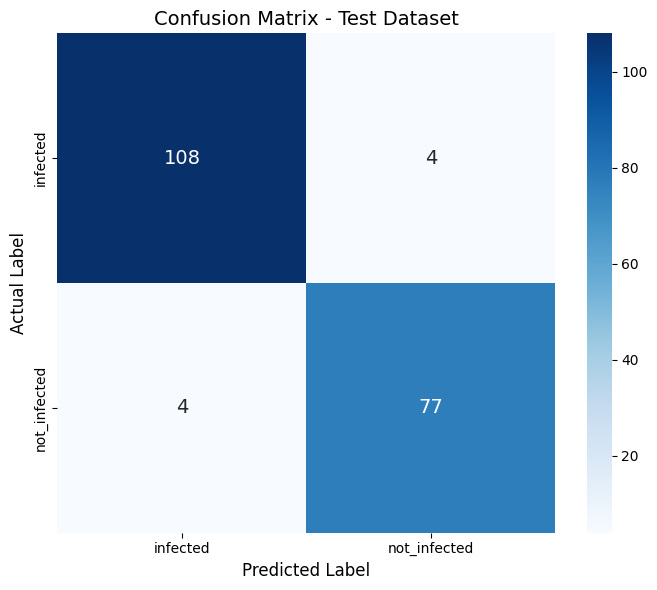


Evaluation files saved successfully:
Test_Performance_Metrics.csv -> Saved
Classification_Report.csv -> Saved
Test_Predictions.csv -> Saved
Confusion_Matrix.png -> Saved

Run Number: 5
Run Seed: 505
Run Directory: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5

CELL 19 COMPLETED SUCCESSFULLY.


In [129]:

# ============================================================
# CELL 19: TEST EVALUATION AND PERFORMANCE METRICS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    cohen_kappa_score
)

# ------------------------------------------------------------
# 1. LOAD BEST MODEL
# ------------------------------------------------------------

BEST_MODEL_PATH = os.path.join(RUN_DIR, "Best_Model.keras")

@tf.keras.utils.register_keras_serializable()
class LearnablePositionEmbedding(tf.keras.layers.Layer):

    def build(self, input_shape):
        sequence_length = input_shape[1]
        embedding_dimension = input_shape[2]

        self.position_embedding = self.add_weight(
            name="position_embedding",
            shape=(1, sequence_length, embedding_dimension),
            initializer=tf.keras.initializers.RandomNormal(),
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        return inputs + self.position_embedding


best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    custom_objects={
        "LearnablePositionEmbedding": LearnablePositionEmbedding
    },
    compile=False
)

print("Best checkpoint loaded successfully.")

# ------------------------------------------------------------
# 2. GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

y_probabilities = best_model.predict(test_ds, verbose=1)

y_pred = np.argmax(y_probabilities, axis=1).astype(int)

# Collect actual labels from test dataset
raw_labels = np.concatenate(
    [labels.numpy() for images, labels in test_ds],
    axis=0
)

# Convert one-hot labels into class indices
if raw_labels.ndim > 1 and raw_labels.shape[-1] == 2:
    y_true = np.argmax(raw_labels, axis=1).astype(int)
else:
    y_true = raw_labels.reshape(-1).astype(int)

# Class probabilities
infected_prob = y_probabilities[:, 0].astype(float)
not_infected_prob = y_probabilities[:, 1].astype(float)

# ------------------------------------------------------------
# 3. VERIFY PREDICTIONS
# ------------------------------------------------------------

print("\nPrediction Verification:")
print("Actual labels:", len(y_true))
print("Predicted labels:", len(y_pred))
print("Probability shape:", y_probabilities.shape)

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)

print("Actual classes:", np.unique(y_true))
print("Predicted classes:", np.unique(y_pred))

assert len(y_true) == len(y_pred), "Label count mismatch!"
assert y_probabilities.shape == (len(y_true), 2), "Probability shape mismatch!"

# ------------------------------------------------------------
# 4. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

# Class 0 = infected (positive class)
TP = cm[0, 0]
FN = cm[0, 1]
FP = cm[1, 0]
TN = cm[1, 1]

print("\nConfusion Matrix Values:")
print("True Positive (TP):", TP)
print("False Negative (FN):", FN)
print("False Positive (FP):", FP)
print("True Negative (TN):", TN)

# ------------------------------------------------------------
# 5. PERFORMANCE METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true, y_pred,
    pos_label=0,
    zero_division=0
)

recall = recall_score(
    y_true, y_pred,
    pos_label=0,
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred,
    pos_label=0,
    zero_division=0
)

sensitivity = recall

specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0

roc_auc = roc_auc_score(
    (y_true == 0).astype(int),
    infected_prob
)

pr_auc = average_precision_score(
    (y_true == 0).astype(int),
    infected_prob
)

mcc = matthews_corrcoef(y_true, y_pred)

kappa = cohen_kappa_score(y_true, y_pred)

# ------------------------------------------------------------
# 6. PRINT PERFORMANCE METRICS
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL TEST PERFORMANCE")
print("=" * 55)

print(f"Test Accuracy       : {accuracy * 100:.4f}%")
print(f"Precision           : {precision * 100:.4f}%")
print(f"Recall              : {recall * 100:.4f}%")
print(f"F1-Score            : {f1 * 100:.4f}%")
print(f"Sensitivity         : {sensitivity * 100:.4f}%")
print(f"Specificity         : {specificity * 100:.4f}%")
print(f"ROC-AUC             : {roc_auc:.4f}")
print(f"PR-AUC (AP)         : {pr_auc:.4f}")
print(f"MCC                 : {mcc:.4f}")
print(f"Cohen's Kappa       : {kappa:.4f}")

print("=" * 55)

# ------------------------------------------------------------
# 7. CLASSIFICATION REPORT
# ------------------------------------------------------------

class_names = ["infected", "not_infected"]

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

# ------------------------------------------------------------
# 8. SAVE PERFORMANCE METRICS
# ------------------------------------------------------------

metrics_dict = {
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Sensitivity",
        "Specificity",
        "ROC-AUC",
        "PR-AUC",
        "MCC",
        "Cohen's Kappa",
        "TP",
        "FN",
        "FP",
        "TN"
    ],

    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        sensitivity,
        specificity,
        roc_auc,
        pr_auc,
        mcc,
        kappa,
        TP,
        FN,
        FP,
        TN
    ]
}

metrics_df = pd.DataFrame(metrics_dict)

metrics_df.to_csv(
    os.path.join(RUN_DIR, "Test_Performance_Metrics.csv"),
    index=False
)

report_df.to_csv(
    os.path.join(RUN_DIR, "Classification_Report.csv")
)

# ------------------------------------------------------------
# 9. SAVE TEST PREDICTIONS
# ------------------------------------------------------------

prediction_df = pd.DataFrame({
    "Sample_Index": np.arange(len(y_true)),
    "Actual_Label": [class_names[i] for i in y_true],
    "Predicted_Label": [class_names[i] for i in y_pred],
    "Actual_Class_Index": y_true,
    "Predicted_Class_Index": y_pred,
    "Infected_Probability": infected_prob,
    "Not_Infected_Probability": not_infected_prob,
    "Correct_Prediction": (y_true == y_pred)
})

prediction_df.to_csv(
    os.path.join(RUN_DIR, "Test_Predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 10. CONFUSION MATRIX VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix - Test Dataset", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)
plt.tight_layout()

plt.savefig(
    os.path.join(RUN_DIR, "Confusion_Matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 11. SAVE FINAL TEST SUMMARY
# ------------------------------------------------------------

print("\nEvaluation files saved successfully:")

saved_files = [
    "Test_Performance_Metrics.csv",
    "Classification_Report.csv",
    "Test_Predictions.csv",
    "Confusion_Matrix.png"
]

for filename in saved_files:
    filepath = os.path.join(RUN_DIR, filename)
    print(
        filename,
        "->",
        "Saved" if os.path.exists(filepath) else "Not found"
    )

print("\nRun Number:", RUN_NUMBER)
print("Run Seed:", RUN_SEED)
print("Run Directory:", RUN_DIR)
print("\nCELL 19 COMPLETED SUCCESSFULLY.")


Actual labels shape: (193,)
Infected probability shape: (193,)


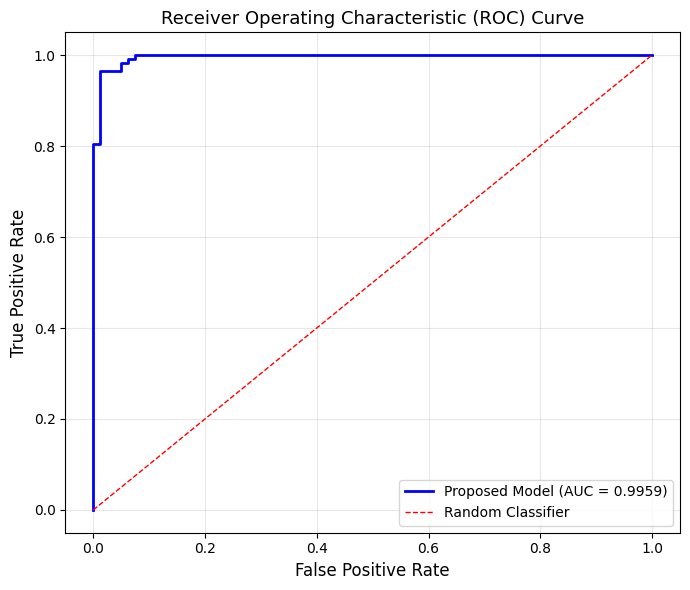

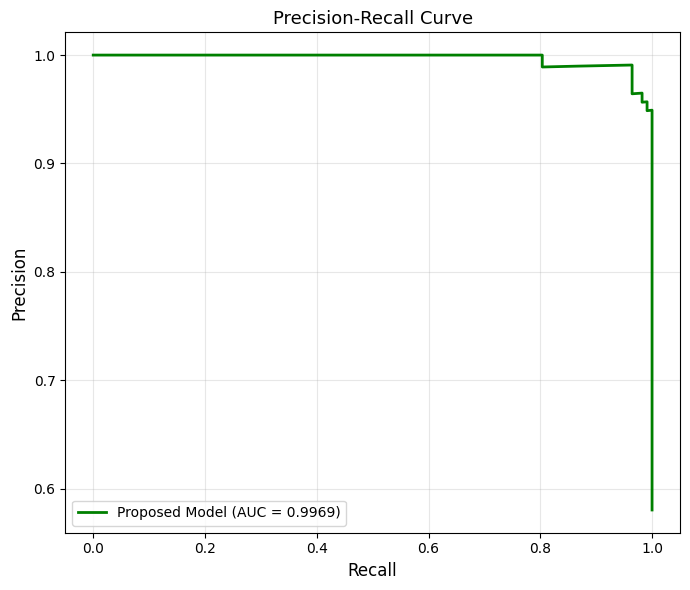


ROC AND PRECISION-RECALL CURVE SUMMARY
ROC-AUC : 0.995922
PR-AUC  : 0.996914

Saved Files:
ROC_Curve_Data.csv -> Saved
ROC_Curve.png -> Saved
ROC_Curve.pdf -> Saved
Precision_Recall_Curve_Data.csv -> Saved
Precision_Recall_Curve.png -> Saved
Precision_Recall_Curve.pdf -> Saved

Experiment Directory:
/content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5

CELL 20 COMPLETED SUCCESSFULLY.
ROC Curve and PR Curve are saved as separate figures.


In [130]:

# ============================================================
# CELL 20: ROC CURVE AND PRECISION-RECALL CURVE
# TWO COMPLETELY SEPARATE FIGURES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

# ------------------------------------------------------------
# 1. PREPARE BINARY LABELS AND PROBABILITIES
# ------------------------------------------------------------

# Positive class = infected (class index 0)

y_true_binary = (y_true == 0).astype(int)

infected_prob = y_probabilities[:, 0]

print("Actual labels shape:", y_true_binary.shape)
print("Infected probability shape:", infected_prob.shape)

# ------------------------------------------------------------
# 2. CALCULATE ROC CURVE
# ------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    y_true_binary,
    infected_prob
)

roc_auc_value = auc(fpr, tpr)

# Save ROC curve numerical data

roc_df = pd.DataFrame({
    "False_Positive_Rate": fpr,
    "True_Positive_Rate": tpr,
    "Threshold": roc_thresholds
})

roc_df.to_csv(
    os.path.join(RUN_DIR, "ROC_Curve_Data.csv"),
    index=False
)

# ------------------------------------------------------------
# 3. ROC CURVE - FIGURE 1
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    color="blue",
    linewidth=2,
    label=f"Proposed Model (AUC = {roc_auc_value:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    color="red",
    linestyle="--",
    linewidth=1,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title(
    "Receiver Operating Characteristic (ROC) Curve",
    fontsize=13
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save ROC figure separately

plt.savefig(
    os.path.join(RUN_DIR, "ROC_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(RUN_DIR, "ROC_Curve.pdf"),
    bbox_inches="tight"
)

# Display only ROC figure

plt.show()

# Completely close ROC figure
plt.close("all")


# ------------------------------------------------------------
# 4. CALCULATE PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(
        y_true_binary,
        infected_prob
    )
)

pr_auc_value = auc(
    recall_values,
    precision_values
)

# Save Precision-Recall numerical data

pr_df = pd.DataFrame({
    "Precision": precision_values,
    "Recall": recall_values
})

pr_df.to_csv(
    os.path.join(RUN_DIR, "Precision_Recall_Curve_Data.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. PRECISION-RECALL CURVE - FIGURE 2
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.plot(
    recall_values,
    precision_values,
    color="green",
    linewidth=2,
    label=f"Proposed Model (AUC = {pr_auc_value:.4f})"
)

plt.xlabel("Recall", fontsize=12)
plt.ylabel("Precision", fontsize=12)

plt.title(
    "Precision-Recall Curve",
    fontsize=13
)

plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()

# Save Precision-Recall figure separately

plt.savefig(
    os.path.join(RUN_DIR, "Precision_Recall_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(RUN_DIR, "Precision_Recall_Curve.pdf"),
    bbox_inches="tight"
)

# Display only Precision-Recall figure

plt.show()

# Completely close Precision-Recall figure
plt.close("all")


# ------------------------------------------------------------
# 6. DISPLAY CURVE SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("ROC AND PRECISION-RECALL CURVE SUMMARY")
print("=" * 60)

print(f"ROC-AUC : {roc_auc_value:.6f}")
print(f"PR-AUC  : {pr_auc_value:.6f}")

print("\nSaved Files:")

saved_files = [
    "ROC_Curve_Data.csv",
    "ROC_Curve.png",
    "ROC_Curve.pdf",
    "Precision_Recall_Curve_Data.csv",
    "Precision_Recall_Curve.png",
    "Precision_Recall_Curve.pdf"
]

for filename in saved_files:

    filepath = os.path.join(RUN_DIR, filename)

    if os.path.exists(filepath):
        print(filename, "-> Saved")
    else:
        print(filename, "-> Not Found")

print("\nExperiment Directory:")
print(RUN_DIR)

print("\nCELL 20 COMPLETED SUCCESSFULLY.")
print("ROC Curve and PR Curve are saved as separate figures.")



Training history loaded successfully.

Available columns:
['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate']


,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.887205,0.321394,0.895288,0.269709,0.0003
1,0.954358,0.139911,0.937173,0.119703,0.0003
2,0.962402,0.122061,0.942408,0.195756,0.0003
3,0.973999,0.099461,0.958115,0.145777,0.0003
4,0.979985,0.058944,0.952880,0.105943,0.0003


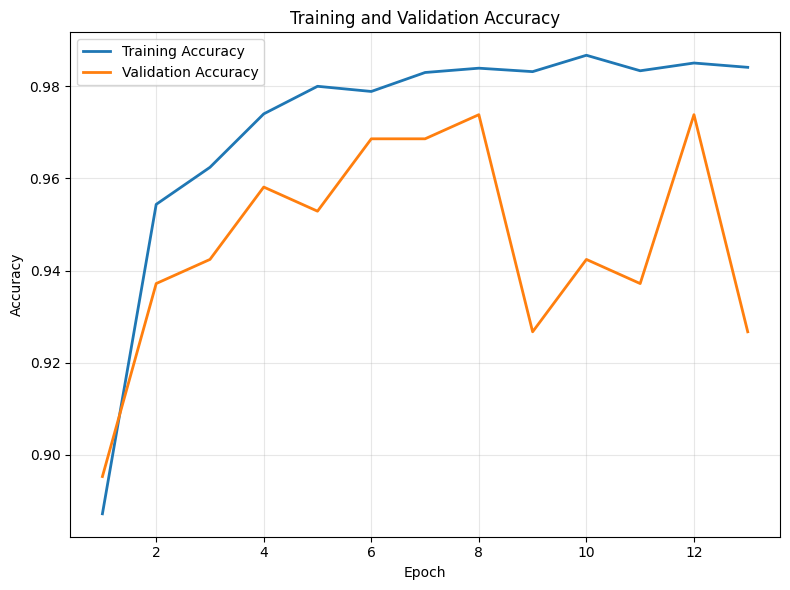

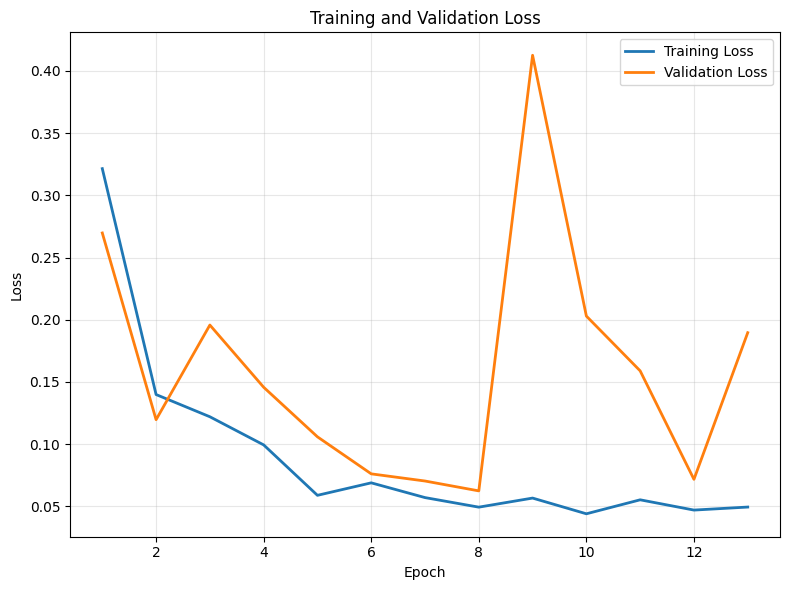


Training history graphs saved successfully.
Accuracy_Curve.png / Accuracy_Curve.pdf
Loss_Curve.png / Loss_Curve.pdf
Training_History_Final.csv


In [131]:
# ============================================================
# CELL 21: TRAINING AND VALIDATION ACCURACY/LOSS CURVES
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. LOAD TRAINING HISTORY
# ------------------------------------------------------------

HISTORY_PATH = os.path.join(
    RUN_DIR,
    "Training_History.csv"
)

history_df = pd.read_csv(HISTORY_PATH)

print("Training history loaded successfully.")
print("\nAvailable columns:")
print(history_df.columns.tolist())

display(history_df.head())

# ------------------------------------------------------------
# 2. IDENTIFY ACCURACY AND LOSS COLUMNS
# ------------------------------------------------------------

accuracy_col = "accuracy"
val_accuracy_col = "val_accuracy"
loss_col = "loss"
val_loss_col = "val_loss"

required_columns = [
    accuracy_col,
    val_accuracy_col,
    loss_col,
    val_loss_col
]

missing_columns = [
    col for col in required_columns
    if col not in history_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

epochs = range(1, len(history_df) + 1)

# ------------------------------------------------------------
# 3. TRAINING AND VALIDATION ACCURACY
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    epochs,
    history_df[accuracy_col],
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history_df[val_accuracy_col],
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RUN_DIR, "Accuracy_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(RUN_DIR, "Accuracy_Curve.pdf"),
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    epochs,
    history_df[loss_col],
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    history_df[val_loss_col],
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(RUN_DIR, "Loss_Curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(RUN_DIR, "Loss_Curve.pdf"),
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. SAVE TRAINING HISTORY COPY
# ------------------------------------------------------------

history_df.to_csv(
    os.path.join(RUN_DIR, "Training_History_Final.csv"),
    index=False
)

print("\nTraining history graphs saved successfully.")
print("Accuracy_Curve.png / Accuracy_Curve.pdf")
print("Loss_Curve.png / Loss_Curve.pdf")
print("Training_History_Final.csv")

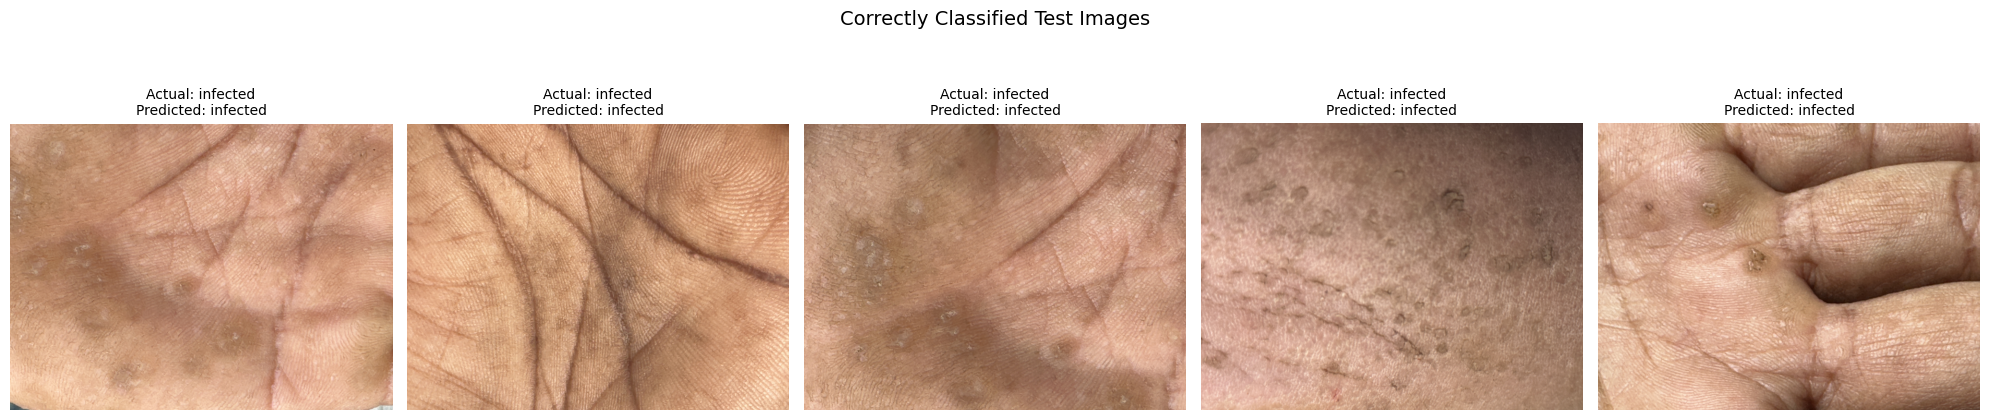

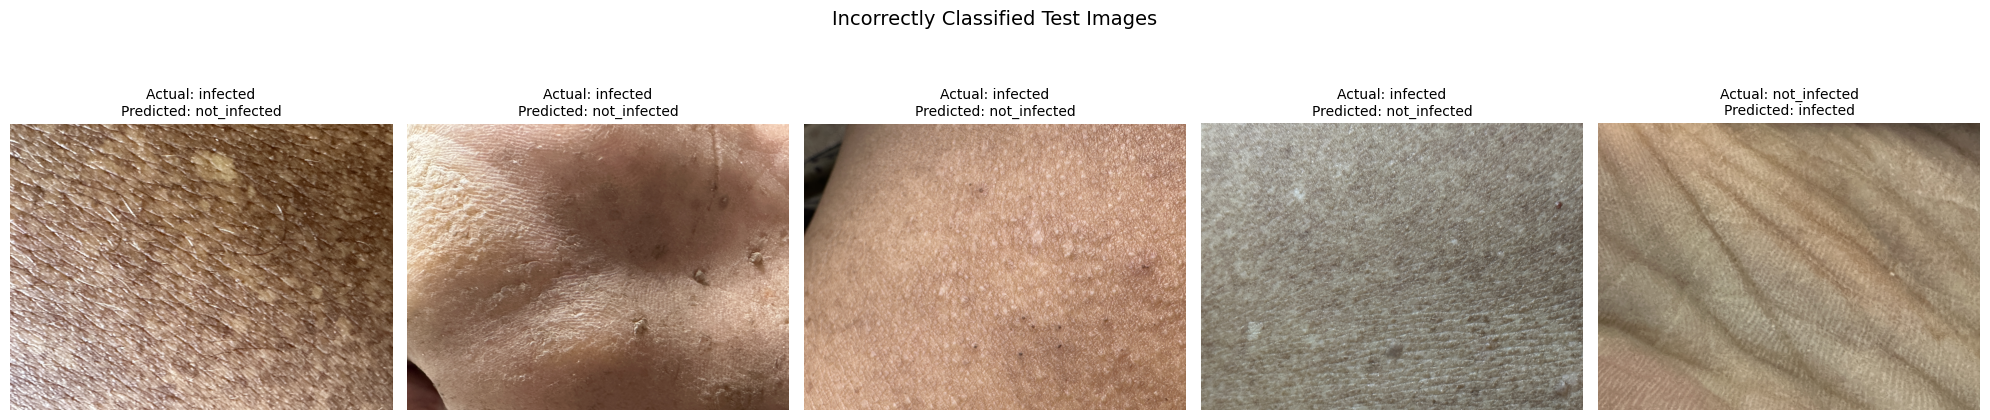

Prediction visualization completed.


In [132]:
# ============================================================
# CELL 22: CORRECT AND INCORRECT PREDICTION VISUALIZATION
# ============================================================

import os
import matplotlib.pyplot as plt
from PIL import Image

# Separate correct and incorrect predictions
correct_df = predictions_df[
    predictions_df["correct_prediction"] == True
].head(5)

incorrect_df = predictions_df[
    predictions_df["correct_prediction"] == False
].head(5)

def show_prediction_samples(data, title, filename):
    if len(data) == 0:
        print(f"No samples available for: {title}")
        return

    fig, axes = plt.subplots(
        1, len(data),
        figsize=(4 * len(data), 5)
    )

    if len(data) == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, data.iterrows()):
        image = Image.open(row["file_path"]).convert("RGB")

        ax.imshow(image)
        ax.set_title(
            f"Actual: {row['actual_class']}\n"
            f"Predicted: {row['predicted_class']}",
            fontsize=10
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()

    plt.savefig(
        os.path.join(RUN_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close(fig)

# Correct predictions
show_prediction_samples(
    correct_df,
    "Correctly Classified Test Images",
    "Correct_Predictions.png"
)

# Incorrect predictions
show_prediction_samples(
    incorrect_df,
    "Incorrectly Classified Test Images",
    "Incorrect_Predictions.png"
)

print("Prediction visualization completed.")

In [133]:
# ============================================================
# CELL 23: FINAL EXPERIMENT SUMMARY
# ============================================================

import os
import json
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Define Summary Information
# ------------------------------------------------------------

summary = {
    "Experiment_Name": EXPERIMENT_NAME,
    "Run_Name": f"Run_{RUN_NUMBER}",
    "Run_Number": int(RUN_NUMBER),
    "Random_Seed": int(RUN_SEED),

    "Model": "EfficientNetV2B0 + Transformer",
    "Number_of_Transformer_Blocks": 2,

    "Dataset_Split": "Leakage-Free Group-Wise Split",
    "Random_State": 42,

    "Image_Size": "224x224",
    "Batch_Size": int(BATCH_SIZE),
    "Maximum_Epochs": int(EPOCHS),

    "Training_Samples": int(len(train_df)),
    "Validation_Samples": int(len(val_df)),
    "Testing_Samples": int(len(test_df))
}

# ------------------------------------------------------------
# 2. Add Test Metrics
# ------------------------------------------------------------

for _, row in metrics_df.iterrows():

    metric_name = str(row["Metric"])
    metric_value = row["Value"]

    if isinstance(metric_value, (np.integer, int)):
        summary[metric_name] = int(metric_value)

    else:
        summary[metric_name] = float(metric_value)

# ------------------------------------------------------------
# 3. Add Training Information
# ------------------------------------------------------------

history_csv_path = os.path.join(
    RUN_DIR,
    "Training_History.csv"
)

if os.path.exists(history_csv_path):

    history_df = pd.read_csv(history_csv_path)

    if "val_accuracy" in history_df.columns:

        best_epoch = int(
            history_df["val_accuracy"].idxmax() + 1
        )

        best_val_accuracy = float(
            history_df["val_accuracy"].max()
        )

        summary["Best_Validation_Accuracy"] = best_val_accuracy
        summary["Best_Validation_Accuracy_Epoch"] = best_epoch

    if "val_loss" in history_df.columns:

        best_val_loss_epoch = int(
            history_df["val_loss"].idxmin() + 1
        )

        best_val_loss = float(
            history_df["val_loss"].min()
        )

        summary["Best_Validation_Loss"] = best_val_loss
        summary["Best_Validation_Loss_Epoch"] = best_val_loss_epoch

    summary["Completed_Epochs"] = int(len(history_df))

# ------------------------------------------------------------
# 4. Save JSON Summary
# ------------------------------------------------------------

summary_json_path = os.path.join(
    RUN_DIR,
    "Final_Experiment_Summary.json"
)

with open(summary_json_path, "w") as file:

    json.dump(
        summary,
        file,
        indent=4
    )

print("Saved:", summary_json_path)

# ------------------------------------------------------------
# 5. Save CSV Summary
# ------------------------------------------------------------

summary_csv_path = os.path.join(
    RUN_DIR,
    "Final_Experiment_Summary.csv"
)

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Parameter", "Value"]
)

summary_df.to_csv(
    summary_csv_path,
    index=False
)

print("Saved:", summary_csv_path)

# ------------------------------------------------------------
# 6. Display Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("FINAL EXPERIMENT SUMMARY")
print("=" * 65)

for key, value in summary.items():

    print(f"{key:38s}: {value}")

print("=" * 65)

print("\nCell 23 completed successfully.")

Saved: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Final_Experiment_Summary.json
Saved: /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5/Final_Experiment_Summary.csv

FINAL EXPERIMENT SUMMARY
Experiment_Name                       : Arsenicosis_EfficientNetV2_Transformer
Run_Name                              : Run_5
Run_Number                            : 5
Random_Seed                           : 505
Model                                 : EfficientNetV2B0 + Transformer
Number_of_Transformer_Blocks          : 2
Dataset_Split                         : Leakage-Free Group-Wise Split
Random_State                          : 42
Image_Size                            : 224x224
Batch_Size                            : 32
Maximum_Epochs                        : 25
Training_Samples                      : 5346
Validation_Samples                    : 191
Testing_Samples                       : 193
Accuracy               

In [134]:
# ============================================================
# CELL 24: ZIP AND BACKUP CURRENT RUN
# ============================================================

import os
import zipfile

# ------------------------------------------------------------
# 1. Define ZIP File Path
# ------------------------------------------------------------

ZIP_FILE_PATH = os.path.join(
    EXPERIMENT_DIR,
    f"Run_{RUN_NUMBER}_Complete_Results.zip"
)

# ------------------------------------------------------------
# 2. Check Run Directory
# ------------------------------------------------------------

if not os.path.isdir(RUN_DIR):

    raise FileNotFoundError(
        f"Run directory not found: {RUN_DIR}"
    )

# ------------------------------------------------------------
# 3. Create ZIP Backup
# ------------------------------------------------------------

if os.path.exists(ZIP_FILE_PATH):

    os.remove(ZIP_FILE_PATH)

with zipfile.ZipFile(
    ZIP_FILE_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(RUN_DIR):

        for file in files:

            file_path = os.path.join(root, file)

            relative_path = os.path.relpath(
                file_path,
                EXPERIMENT_DIR
            )

            zipf.write(
                file_path,
                arcname=relative_path
            )

# ------------------------------------------------------------
# 4. Verify ZIP File
# ------------------------------------------------------------

if os.path.exists(ZIP_FILE_PATH):

    zip_size_mb = os.path.getsize(
        ZIP_FILE_PATH
    ) / (1024 * 1024)

    with zipfile.ZipFile(ZIP_FILE_PATH, "r") as zipf:

        zip_contents = zipf.namelist()

        bad_file = zipf.testzip()

    if bad_file is not None:

        raise RuntimeError(
            f"ZIP verification failed: {bad_file}"
        )

    print("=" * 60)
    print("RUN BACKUP COMPLETED SUCCESSFULLY")
    print("=" * 60)

    print("Run Number :", RUN_NUMBER)
    print("Run Folder :", RUN_DIR)
    print("ZIP File   :", ZIP_FILE_PATH)
    print(f"ZIP Size   : {zip_size_mb:.2f} MB")
    print("Files      :", len(zip_contents))
    print("ZIP Status : Verified")

    print("=" * 60)

else:

    raise RuntimeError(
        "ZIP file was not created successfully."
    )

print("\nCell 24 completed successfully.")

RUN BACKUP COMPLETED SUCCESSFULLY
Run Number : 5
Run Folder : /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5
ZIP File   : /content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Run_5_Complete_Results.zip
ZIP Size   : 326.60 MB
Files      : 23
ZIP Status : Verified

Cell 24 completed successfully.


In [135]:
# ============================================================
# CELL 25: FINAL OUTPUT FILE VERIFICATION
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 1. Define Expected Output Files
# ------------------------------------------------------------

expected_files = [
    "Best_Model.keras",
    "Class_Weights.json",
    "Training_History.csv",

    "Test_Predictions.csv",
    "Test_Metrics.csv",
    "Confusion_Matrix.csv",
    "Classification_Report.csv",
    "Confusion_Matrix.png",
    "Confusion_Matrix.pdf",

    "ROC_Curve.csv",
    "PR_Curve.csv",
    "ROC_Curve.png",
    "ROC_Curve.pdf",
    "PR_Curve.png",
    "PR_Curve.pdf",

    "Training_Accuracy_Loss_Curves.png",
    "Training_Accuracy_Loss_Curves.pdf",

    "Correct_Predictions",
    "Incorrect_Predictions",

    "Final_Experiment_Summary.json",
    "Final_Experiment_Summary.csv"
]

# ------------------------------------------------------------
# 2. Verify Each Output
# ------------------------------------------------------------

verification_results = []

for item in expected_files:

    item_path = os.path.join(RUN_DIR, item)

    if os.path.isfile(item_path):

        status = "FOUND"
        item_type = "File"
        size_mb = os.path.getsize(item_path) / (1024 * 1024)

    elif os.path.isdir(item_path):

        status = "FOUND"
        item_type = "Folder"
        size_mb = 0

    else:

        status = "MISSING"
        item_type = "Not Found"
        size_mb = 0

    verification_results.append({
        "Output_Name": item,
        "Type": item_type,
        "Status": status,
        "Size_MB": round(size_mb, 4)
    })

# ------------------------------------------------------------
# 3. Create Verification DataFrame
# ------------------------------------------------------------

verification_df = pd.DataFrame(
    verification_results
)

# ------------------------------------------------------------
# 4. Save Verification Report
# ------------------------------------------------------------

verification_csv_path = os.path.join(
    RUN_DIR,
    "Output_File_Verification.csv"
)

verification_df.to_csv(
    verification_csv_path,
    index=False
)

# ------------------------------------------------------------
# 5. Display Verification Results
# ------------------------------------------------------------

print("=" * 70)
print(f"OUTPUT FILE VERIFICATION - RUN {RUN_NUMBER}")
print("=" * 70)

print(verification_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Verification Summary
# ------------------------------------------------------------

total_outputs = len(verification_df)

found_outputs = (
    verification_df["Status"] == "FOUND"
).sum()

missing_outputs = (
    verification_df["Status"] == "MISSING"
).sum()

print("\n" + "=" * 70)
print("VERIFICATION SUMMARY")
print("=" * 70)

print("Run Number       :", RUN_NUMBER)
print("Run Directory    :", RUN_DIR)
print("Total Outputs    :", total_outputs)
print("Found Outputs    :", found_outputs)
print("Missing Outputs  :", missing_outputs)

print("Verification CSV :", verification_csv_path)

if missing_outputs == 0:

    print("\nALL EXPECTED OUTPUTS FOUND.")

else:

    print("\nWARNING: SOME EXPECTED OUTPUTS ARE MISSING.")

    print("\nMissing Files:")

    print(
        verification_df.loc[
            verification_df["Status"] == "MISSING",
            "Output_Name"
        ].to_list()
    )

print("=" * 70)

print("\nCell 25 completed successfully.")

OUTPUT FILE VERIFICATION - RUN 5
                      Output_Name      Type  Status  Size_MB
                 Best_Model.keras      File   FOUND 339.9210
               Class_Weights.json Not Found MISSING   0.0000
             Training_History.csv      File   FOUND   0.0013
             Test_Predictions.csv      File   FOUND   0.0139
                 Test_Metrics.csv Not Found MISSING   0.0000
             Confusion_Matrix.csv Not Found MISSING   0.0000
        Classification_Report.csv      File   FOUND   0.0004
             Confusion_Matrix.png      File   FOUND   0.0847
             Confusion_Matrix.pdf Not Found MISSING   0.0000
                    ROC_Curve.csv Not Found MISSING   0.0000
                     PR_Curve.csv Not Found MISSING   0.0000
                    ROC_Curve.png      File   FOUND   0.1313
                    ROC_Curve.pdf      File   FOUND   0.0151
                     PR_Curve.png Not Found MISSING   0.0000
                     PR_Curve.pdf Not Found MISSING 

In [136]:

# ============================================================
# FINAL CELL: AUTOMATIC 5-RUN PERFORMANCE COMPARISON
# Calculates Mean and Standard Deviation across Run_1 to Run_5
# ============================================================

import os
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. EXPERIMENT DIRECTORY
# ------------------------------------------------------------

BASE_EXPERIMENT_DIR = os.path.join(
    EXPERIMENT_DIR
)

TOTAL_RUNS = 5

# ------------------------------------------------------------
# 2. METRICS TO INCLUDE IN FINAL ANALYSIS
# ------------------------------------------------------------

required_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Sensitivity",
    "Specificity",
    "ROC-AUC",
    "PR-AUC",
    "MCC",
    "Cohen's Kappa"
]

# Metrics originally stored as proportions (0 to 1)
percentage_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Sensitivity",
    "Specificity"
]

# ------------------------------------------------------------
# 3. LOAD METRICS FROM ALL FIVE RUNS
# ------------------------------------------------------------

all_run_results = []

for run_number in range(1, TOTAL_RUNS + 1):

    run_folder = os.path.join(
        BASE_EXPERIMENT_DIR,
        f"Run_{run_number}"
    )

    metrics_file = os.path.join(
        run_folder,
        "Test_Performance_Metrics.csv"
    )

    if not os.path.exists(metrics_file):
        raise FileNotFoundError(
            f"Missing metrics file for Run_{run_number}: "
            f"{metrics_file}"
        )

    metrics_df = pd.read_csv(metrics_file)

    run_result = {
        "Run": f"Run_{run_number}"
    }

    for metric in required_metrics:

        matching_row = metrics_df.loc[
            metrics_df["Metric"] == metric,
            "Value"
        ]

        if matching_row.empty:
            raise ValueError(
                f"{metric} not found in Run_{run_number}"
            )

        run_result[metric] = float(
            matching_row.iloc[0]
        )

    all_run_results.append(run_result)

print("All five runs loaded successfully.")

# ------------------------------------------------------------
# 4. CREATE INDIVIDUAL RUN COMPARISON TABLE
# ------------------------------------------------------------

individual_results_df = pd.DataFrame(
    all_run_results
)

print("\n" + "=" * 90)
print("INDIVIDUAL TEST PERFORMANCE OF FIVE RUNS")
print("=" * 90)

display(individual_results_df)

# ------------------------------------------------------------
# 5. CALCULATE MEAN AND STANDARD DEVIATION
# ------------------------------------------------------------

summary_rows = []

for metric in required_metrics:

    values = individual_results_df[metric].astype(float)

    mean_value = values.mean()

    # Sample standard deviation (ddof=1)
    std_value = values.std(ddof=1)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "Standard_Deviation": std_value,
        "Mean ± SD": (
            f"{mean_value * 100:.2f} ± {std_value * 100:.2f}%"
            if metric in percentage_metrics
            else f"{mean_value:.4f} ± {std_value:.4f}"
        )
    })

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# 6. DISPLAY FINAL MEAN ± SD TABLE
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL FIVE-RUN PERFORMANCE: MEAN ± STANDARD DEVIATION")
print("=" * 90)

display(summary_df)

# ------------------------------------------------------------
# 7. SAVE FINAL RESULTS
# ------------------------------------------------------------

comparison_csv = os.path.join(
    BASE_EXPERIMENT_DIR,
    "Final_5_Run_Individual_Results.csv"
)

summary_csv = os.path.join(
    BASE_EXPERIMENT_DIR,
    "Final_5_Run_Mean_SD.csv"
)

excel_file = os.path.join(
    BASE_EXPERIMENT_DIR,
    "Final_5_Run_Complete_Analysis.xlsx"
)

# Save individual results
individual_results_df.to_csv(
    comparison_csv,
    index=False
)

# Save Mean ± SD results
summary_df.to_csv(
    summary_csv,
    index=False
)

# Save both tables in one Excel workbook
with pd.ExcelWriter(excel_file) as writer:

    individual_results_df.to_excel(
        writer,
        sheet_name="Individual_Run_Results",
        index=False
    )

    summary_df.to_excel(
        writer,
        sheet_name="Mean_SD_Summary",
        index=False
    )

# ------------------------------------------------------------
# 8. FINAL CONFIRMATION
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FIVE-RUN ANALYSIS COMPLETED SUCCESSFULLY")
print("=" * 90)

print("Runs analyzed:", TOTAL_RUNS)

print("\nSaved files:")
print(comparison_csv)
print(summary_csv)
print(excel_file)

print("\nAll five runs have been included in the final analysis.")
print("Mean and sample standard deviation calculated successfully.")

print("=" * 90)


All five runs loaded successfully.

INDIVIDUAL TEST PERFORMANCE OF FIVE RUNS


,Run,Accuracy,Precision,Recall,F1-Score,Sensitivity,Specificity,ROC-AUC,PR-AUC,MCC,Cohen's Kappa
0,Run_1,0.953368,0.940171,0.982143,0.960699,0.982143,0.913580,0.988205,0.991235,0.904744,0.903441
1,Run_2,0.953368,0.955752,0.964286,0.960000,0.964286,0.938272,0.991402,0.994630,0.904153,0.904102
2,Run_3,0.979275,0.973684,0.991071,0.982301,0.991071,0.962963,0.998567,0.999006,0.957524,0.957306
3,Run_4,0.974093,0.973451,0.982143,0.977778,0.982143,0.962963,0.994599,0.995710,0.946777,0.946723
4,Run_5,0.958549,0.964286,0.964286,0.964286,0.964286,0.950617,0.995922,0.996928,0.914903,0.914903



FINAL FIVE-RUN PERFORMANCE: MEAN ± STANDARD DEVIATION


,Metric,Mean,Standard_Deviation,Mean ± SD
0,Accuracy,0.963731,0.012151,96.37 ± 1.22%
1,Precision,0.961469,0.014027,96.15 ± 1.40%
2,Recall,0.976786,0.011979,97.68 ± 1.20%
3,F1-Score,0.969013,0.010321,96.90 ± 1.03%
4,Sensitivity,0.976786,0.011979,97.68 ± 1.20%
5,Specificity,0.945679,0.020658,94.57 ± 2.07%
6,ROC-AUC,0.993739,0.004028,0.9937 ± 0.0040
7,PR-AUC,0.995502,0.002886,0.9955 ± 0.0029
8,MCC,0.925620,0.024885,0.9256 ± 0.0249
9,Cohen's Kappa,0.925295,0.025093,0.9253 ± 0.0251



FIVE-RUN ANALYSIS COMPLETED SUCCESSFULLY
Runs analyzed: 5

Saved files:
/content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Final_5_Run_Individual_Results.csv
/content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Final_5_Run_Mean_SD.csv
/content/drive/MyDrive/Thesis_Experiments/Arsenicosis_EfficientNetV2_Transformer/Final_5_Run_Complete_Analysis.xlsx

All five runs have been included in the final analysis.
Mean and sample standard deviation calculated successfully.
